# Projeto Extensionista - Notebook de EDA (Análise Exploratória de Dados)
**Nomes:** Amanda Flores Domeneghini, Milena Fontana Bregalda, Mariana Nunes dos Santos, Karen Cristiane Nascimento


**Disciplina**: Coleta, Preparação e Análise de Dados


**Turma**: 310/110

**Professora**: Katherine Bianchini Esper


**Data**: 09/11/2026

1. Se o nível do Guaíba sobe de 3 a 10 metros, como é distribuída a população afetada e a proporção de prédios atingidos? (Tela 1)
2. Como estão distribuídas geograficamente as Casas de Bomba? (API 1)
3. Como se distribuem as frequências das cotas mínimas de alagamento identificadas nas casas de bomba nos polígonos mapeados da cidade? (API 2)
4. Qual é o nível mais baixo de alagamento simulado pelo INCT que atinge ou ultrapassa a menor cota de inundação associada a cada Casa de Bomba? (Dados de diferentes fontes agregados)
5. Como varia a quantidade de Casas de Bomba potencialmente atingidas conforme o nível de alagamento simulado pelo INCT? (Dados de diferentes fontes agregados)
6. Quando o nível do Guaíba vai subindo, como se compara visualmente o aumento da simulação de pessoas afetadas, de acordo com o aumento de casas de bomba que foram potencialmente atingidas pela água? (Dados de diferentes fontes agregados)

### 1. Se o nível do Guaíba sobe de 3 a 10 metros, como é distribuída a população afetada e a proporção de prédios atingidos?
O gráfico cruza no eixo X o nível simulado do Guaíba (de 3,0 m a 10,0 m) com duas métricas principais no eixo Y: a população afetada total (curva vermelha, à esquerda) e a média do percentual de prédios afetados por bairro (curva azul, à direita). A medida que o nível sobe, tanto a população quanto os prédios afetados sobem. A linha com traços se refere ao recorde de 5,35 metros de 2024. 

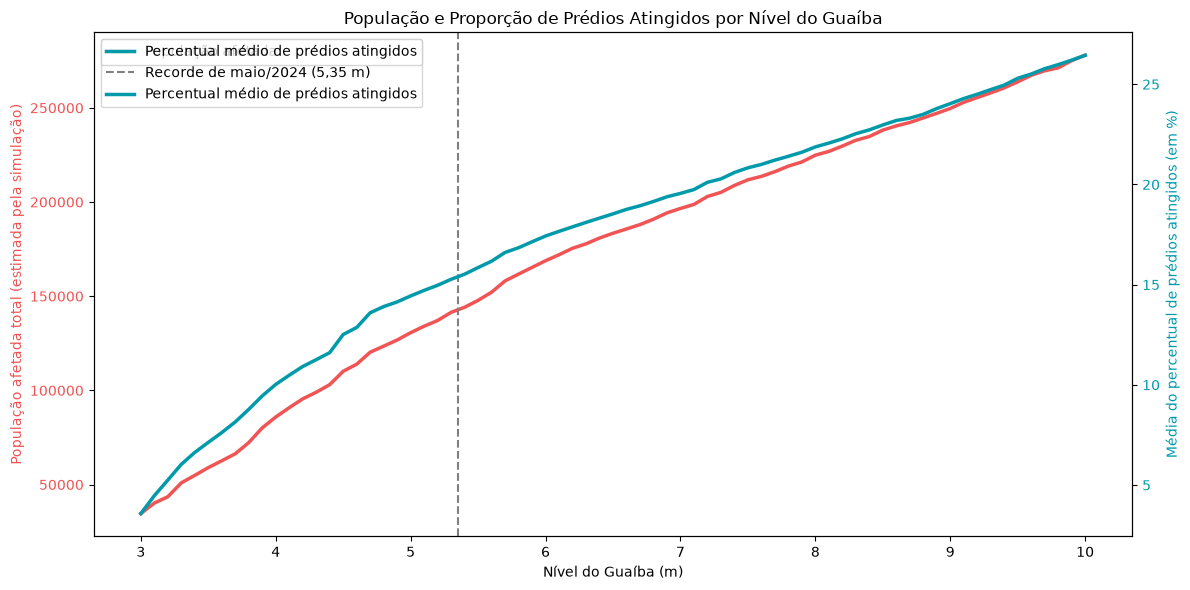

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carrega os dados do JSON do INCT
df = pd.read_json("../dados/processados/data_inctlongoelimpo.json")

# Agrupando os dados por nível do Guaíba
resumo_nivel = df.groupby("nivel_m").agg(
    populacao_afetada=("affected_population", "sum"),
    percentual_predios=("percentage", "mean")
).reset_index()

# Cria grafico com 2 eixos pra conseguir responder a pergunta
fig, ax1 = plt.subplots(figsize=(12, 6))

# Define comportamento da linha eixo x - da populacao afetada
sns.lineplot(
    data=resumo_nivel,
    x="nivel_m",
    y="populacao_afetada",
    ax=ax1,
    color="#F05454",
    linewidth=2.5,
    label="População afetada"
)

ax1.set_xlabel("Nível do Guaíba (m)")
ax1.set_ylabel("População afetada total (estimada pela simulação)", color="#F05454")
ax1.tick_params(axis="y", labelcolor="#F05454")

# # Define comportamento da linha eixo y da - percentual médio de prédios atingidos
ax2 = ax1.twinx() # twinx cria segundo eixo vertical (y)

sns.lineplot(
    data=resumo_nivel,
    x="nivel_m",
    y="percentual_predios",
    ax=ax2,
    color="#009AAB",
    linewidth=2.5,
    label="Percentual médio de prédios atingidos"
)

ax2.set_ylabel("Média do percentual de prédios atingidos (em %)", color="#009AAB")
ax2.tick_params(axis="y", labelcolor="#009AAB") # tick_params pra texto ter cor diferente e os 2 eixos nao confundirem

# Maio de 2024 marcado no grafico
ax1.axvline(
    x=5.35,
    color="gray",
    linestyle="--",
    label="Recorde de maio/2024 (5,35 m)"
)

# Legendas dos dois eixos:
lines_1, labels_1 = ax1.get_legend_handles_labels() # get_legend_handles_labels pra juntar as legendas
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

# Configuracoes finais do grafico:
plt.title("População e Proporção de Prédios Atingidos por Nível do Guaíba")
plt.tight_layout()
plt.show()


### 2. Como estão distribuídas geograficamente as Casas de Bomba? (API 1)
O gráfico apresenta a distribuição geográfica das 24 Casas de Bomba de Porto Alegre, utilizando a longitude no eixo X e a latitude no eixo Y. Cada ponto representa uma unidade, que é identificada por uma cor diferente e pelo respectivo nome na legenda. Assim, é possível visualizar a localização e a distribuição espacial das casas de bomba pelo território da cidade.

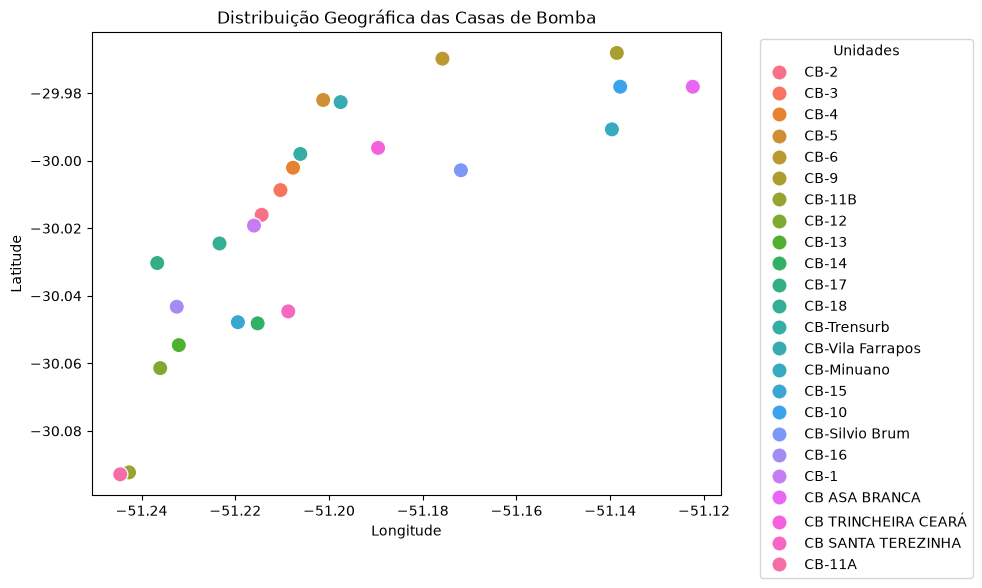

In [13]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open("../dados/processados/pipeline_casas_limpas.json", encoding="utf-8") as f:
    dados = json.load(f)

df_bombas = pd.DataFrame(dados)

# Configura grafico de distribuicao geografica
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_bombas,
    x="longitude",
    y="latitude",
    hue="nome",
    s=120,
)

plt.title("Distribuição Geográfica das Casas de Bomba")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", title="Unidades")
plt.tight_layout()
plt.show()

### 3. Como se distribuem as frequências das cotas mínimas de alagamento identificadas nas casas de bomba nos polígonos mapeados da cidade? (API 2)
O gráfico apresenta no eixo X as cotas mínimas/menor nível de alagamento identificadas nas casas de bomba (em metros) e, no eixo Y, a quantidade de casas de bomba (que apresentam cada cota). As barras representam a frequência de ocorrência de cada nível, o que permite identificar quais cotas mínimas são mais recorrentes entre as unidades analisadas.

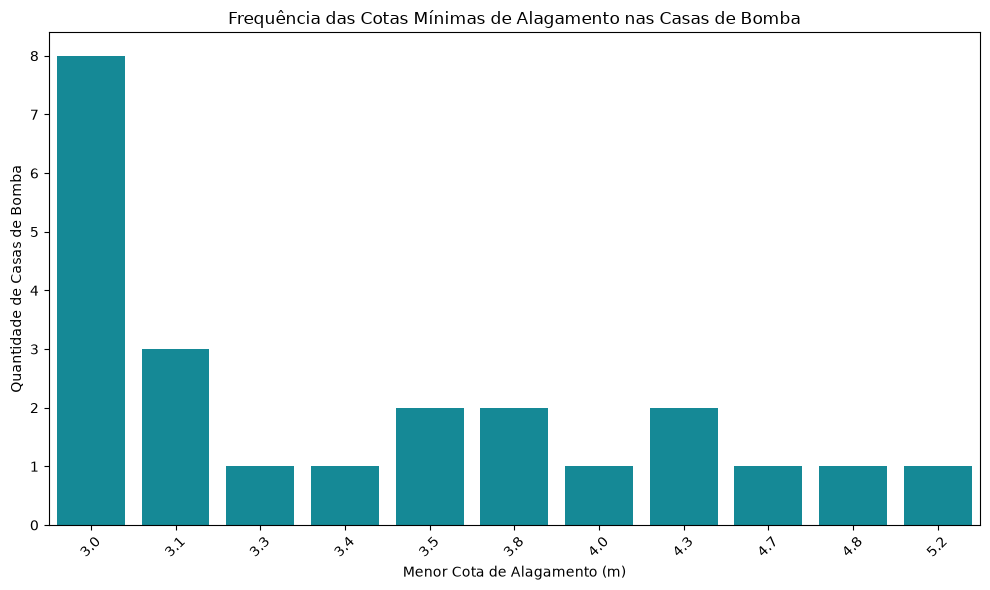

In [20]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open("../dados/processados/pipeline_cotas_resumo.json", encoding="utf-8") as f:
    dados = json.load(f)

df_cotas = pd.DataFrame(dados)

# A limpeza foi feita, mas so pra garantir
df_cotas = df_cotas.dropna(subset=["menor_cota_m"])

# Frequencia de cada menor cota
frequencias = df_cotas["menor_cota_m"].value_counts().sort_index()

# Configura o grafico
plt.figure(figsize=(10, 6))

sns.barplot(
    x=frequencias.index,
    y=frequencias.values,
    color="#009AAB",
)

plt.title("Frequência das Cotas Mínimas de Alagamento nas Casas de Bomba")
plt.xlabel("Menor Cota de Alagamento (m)")
plt.ylabel("Quantidade de Casas de Bomba")
plt.xticks(rotation=45)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()


### 4. Qual é o nível mais baixo de alagamento simulado pelo INCT que atinge ou ultrapassa a menor cota de inundação associada a cada Casa de Bomba? (Dados de diferentes fontes agregados)
O gráfico apresenta no eixo X cada Casa de Bomba, e no eixo Y o primeiro nível de alagamento/mais baixo simulado pelo INCT que atinge ou ultrapassa a menor cota de inundação associada à localização. É possível identificar o nível mínimo simulado em que cada Casa de Bomba é potencialmente atingida, considerando que duas fontes foram utilizadas juntas para responder à pergunta.

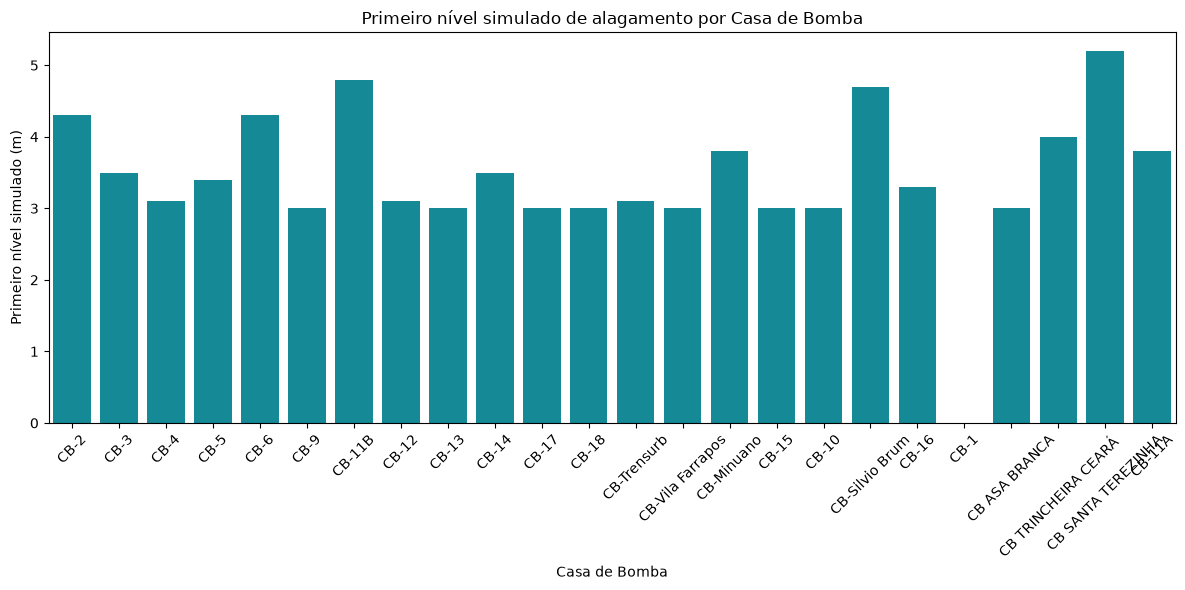

In [22]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dados de duas fontes diferentes:
with open("../dados/processados/pipeline_cotas_resumo.json", encoding="utf-8") as f:
    dados_cotas = json.load(f)

df_cotas = pd.DataFrame(dados_cotas)

with open("../dados/processados/data_inctlongoelimpo.json", encoding="utf-8") as f:
    dados_inct = json.load(f)

df_inct = pd.DataFrame(dados_inct)

# A limpeza foi feita, mas so pra garantir
niveis = df_inct[["nivel_m"]].drop_duplicates()

# Combina cada casa de bomba com os níveis simulados
cruzamento = pd.merge(df_cotas, niveis, how="cross")

# Acha os níveis que atingem ou ultrapassam a cota mínima
atingidas = cruzamento[
    cruzamento["nivel_m"] >= cruzamento["menor_cota_m"]
]

# Encontra o primeiro nível simulado para cada casa
primeiro_nivel = (
    atingidas.sort_values("nivel_m")
    .drop_duplicates(subset=["fid", "nome"])
    [["fid", "nome", "nivel_m"]]
)

# Organiza e mostra resultados
resultado = pd.merge(
    df_cotas[["fid", "nome", "menor_cota_m"]],
    primeiro_nivel,
    on=["fid", "nome"],
    how="left"
)

resultado = resultado.rename(columns={
    "menor_cota_m": "cota_minima_m",
    "nivel_m": "primeiro_nivel_simulado_m"
})

# Grafico
plt.figure(figsize=(12, 6))

sns.barplot(
    data=resultado,
    x="nome",
    y="primeiro_nivel_simulado_m",
    color="#009AAB"
)

plt.title("Primeiro nível simulado de alagamento por Casa de Bomba")
plt.xlabel("Casa de Bomba")
plt.ylabel("Primeiro nível simulado (m)")
plt.xticks(rotation=45)
plt.ylim(bottom=0)

plt.tight_layout()
plt.show()

### 5. Como varia a quantidade de Casas de Bomba potencialmente atingidas conforme o nível de alagamento simulado pelo INCT? (Dados de diferentes fontes agregados)
O gráfico apresenta a quantidade de Casas de Bomba potencialmente atingidas pelo alagamento para cada nível simulado do Guaíba. À medida que o nível da água aumenta, é possível observar como cresce a quantidade de unidades localizadas em áreas de alagamento. O gráfico identifica a partir de qual nível as Casas de Bomba começam a ser atingidas, e como esse número evolui conforme a elevação do rio.

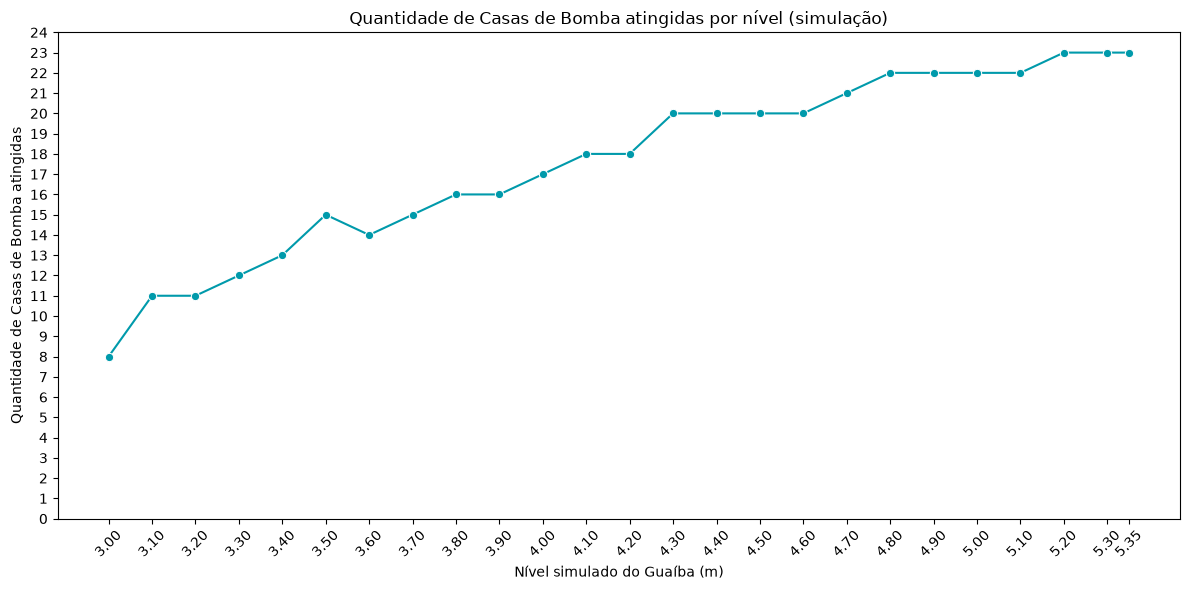

In [16]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

with open("../dados/processados/pipeline_casas_por_nivel.json", encoding="utf-8") as f:
    dados = json.load(f)

df = pd.DataFrame(dados)

# Filtra as casas de bomba que foram atingidas pelo alagamento
atingidas = df[df["intersecao_retornada"] == True]

# Conta as casas atingidas por nivel e ordena
resumo = atingidas.groupby("nivel_m")["fid"].nunique().reset_index()
resumo = resumo.sort_values("nivel_m")

# Configura grafico
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=resumo,
    x="nivel_m",
    y="fid",
    marker="o",
    color="#009AAB",
)

plt.title("Quantidade de Casas de Bomba atingidas por nível (simulação)")
plt.xlabel("Nível simulado do Guaíba (m)")
plt.ylabel("Quantidade de Casas de Bomba atingidas")
plt.xticks(sorted(df["nivel_m"].unique()), rotation=45)
plt.yticks(range(0, df["fid"].nunique() + 1))

plt.tight_layout()
plt.show()

### 6. Quando o nível do Guaíba vai subindo, como se compara visualmente o aumento da simulação de pessoas afetadas, de acordo com o aumento de casas de bomba que foram potencialmente atingidas pela água? (Dados de diferentes fontes agregados)
O gráfico cruza no eixo X o nível simulado do Guaíba com duas métricas principais no eixo Y: a quantidade total de pessoas afetadas (curva vermelha, à esquerda) e a quantidade de Casas de Bomba potencialmente atingidas (curva azul, à direita). À medida que o nível do Guaíba sobe, é possível observar como a população afetada e a quantidade de Casas de Bomba atingidas evoluem. A análise combina dados de diferentes fontes: as simulações de população afetada do INCT SiMAI, e os dados de localização das Casas de Bomba cruzados com as áreas de inundação.

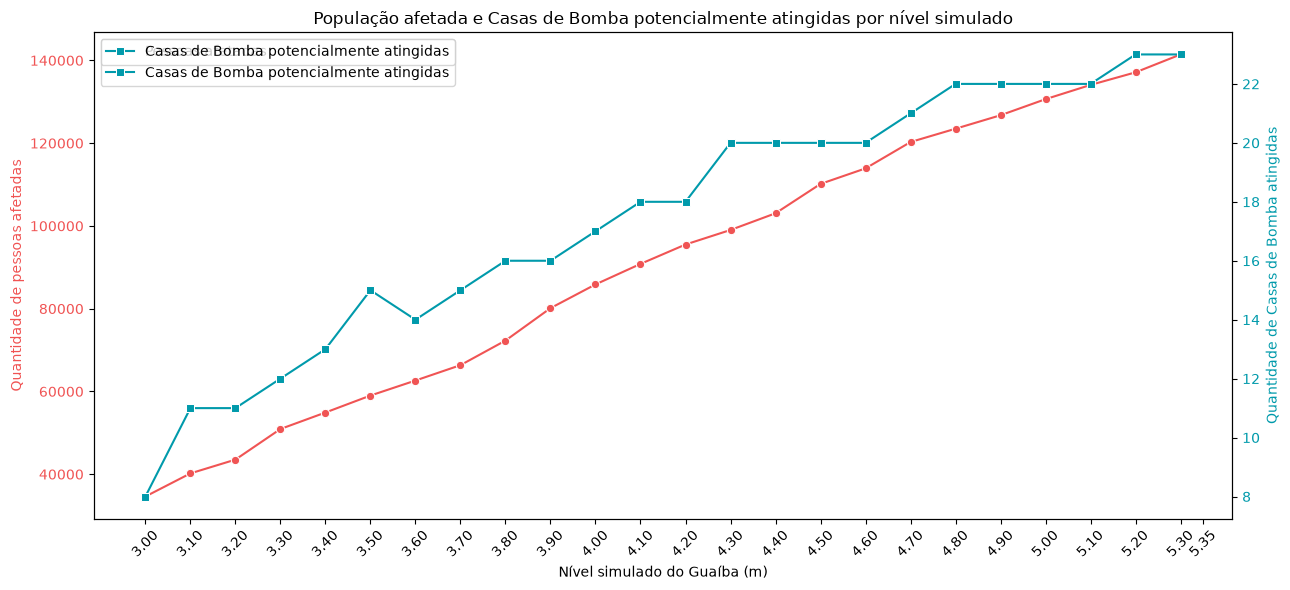

In [17]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carrega dos dados do INCT
with open("../dados/processados/data_inctlongoelimpo.json", encoding="utf-8") as f:
    dados_inct = json.load(f)

df_inct = pd.DataFrame(dados_inct)

# Soma pra cada nivel simulado
populacao = (
    df_inct
    .groupby("nivel_m")["affected_population"]
    .sum()
    .reset_index(name="pessoas_afetadas")
)

# Carrega os dados com casas de bomba
with open("../dados/processados/pipeline_casas_por_nivel.json", encoding="utf-8") as f:
    dados_bombas = json.load(f)

df_bombas = pd.DataFrame(dados_bombas)

# Soma pra cada nivel simulado das casas potencialmente atingidas
atingidas = df_bombas[
    df_bombas["intersecao_retornada"] == True
]

bombas = (
    atingidas
    .groupby("nivel_m")["fid"]
    .nunique()
    .reset_index(name="casas_bomba_atingidas")
)

# No grafico aparecem os niveis que nao eh atingido tambem para melhor visualizacao
# unique para so aparecer 1x
niveis = sorted(df_bombas["nivel_m"].dropna().unique())

bombas = (
    bombas
    .set_index("nivel_m")
    .reindex(niveis, fill_value=0)
    .rename_axis("nivel_m")
    .reset_index()
)

# Combina dados das fontes
resultado = pd.merge(
    populacao,
    bombas,
    on="nivel_m",
    how="inner"
).sort_values("nivel_m")

# Configura grafico
fig, ax1 = plt.subplots(figsize=(13, 6))

sns.lineplot(
    data=resultado,
    x="nivel_m",
    y="pessoas_afetadas",
    marker="o",
    color="#F05454",
    ax=ax1,
    label="Pessoas afetadas"
)

ax1.set_xlabel("Nível simulado do Guaíba (m)")
ax1.set_ylabel("Quantidade de pessoas afetadas", color="#F05454")
ax1.tick_params(axis="y", labelcolor="#F05454")

ax2 = ax1.twinx() # eixo y com twinx

sns.lineplot(
    data=resultado,
    x="nivel_m",
    y="casas_bomba_atingidas",
    marker="s",
    color="#009AAB",
    ax=ax2,
    label="Casas de Bomba potencialmente atingidas"
)

ax2.set_ylabel("Quantidade de Casas de Bomba atingidas", color="#009AAB")
ax2.tick_params(axis="y", labelcolor="#009AAB")

ax1.set_title(
    "População afetada e Casas de Bomba potencialmente atingidas por nível simulado"
)

ax1.set_xticks(niveis)
ax1.tick_params(axis="x", rotation=45)

# Junta as legendas
linhas1, legendas1 = ax1.get_legend_handles_labels()
linhas2, legendas2 = ax2.get_legend_handles_labels()

ax1.legend(
    linhas1 + linhas2,
    legendas1 + legendas2,
    loc="upper left"
)

plt.tight_layout()
plt.show()